In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sqlalchemy import create_engine, text
from prophet import Prophet
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import openpyxl
from openpyxl.styles import (PatternFill, Font, Alignment,
                              Border, Side, GradientFill)
from openpyxl.chart import BarChart, LineChart, Reference
from openpyxl.utils.dataframe import dataframe_to_rows
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi":        150,
    "figure.figsize":    (14, 5),
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.titlesize":    14,
    "axes.titleweight":  "bold",
    "font.family":       "sans-serif",
})

DB_PATH = r"D:\customer_intelligence_platform\data\processed\olist.db"
engine  = create_engine(f"sqlite:///{DB_PATH}")

def sql(query):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)

print("Ready for forecasting")

Ready for forecasting


   Time series built
   Date range : 2017-01-05 → 2018-08-29
   Total days : 602
   Avg daily orders  : 160
   Avg daily revenue : $25,541
   Peak orders in a day: 1147


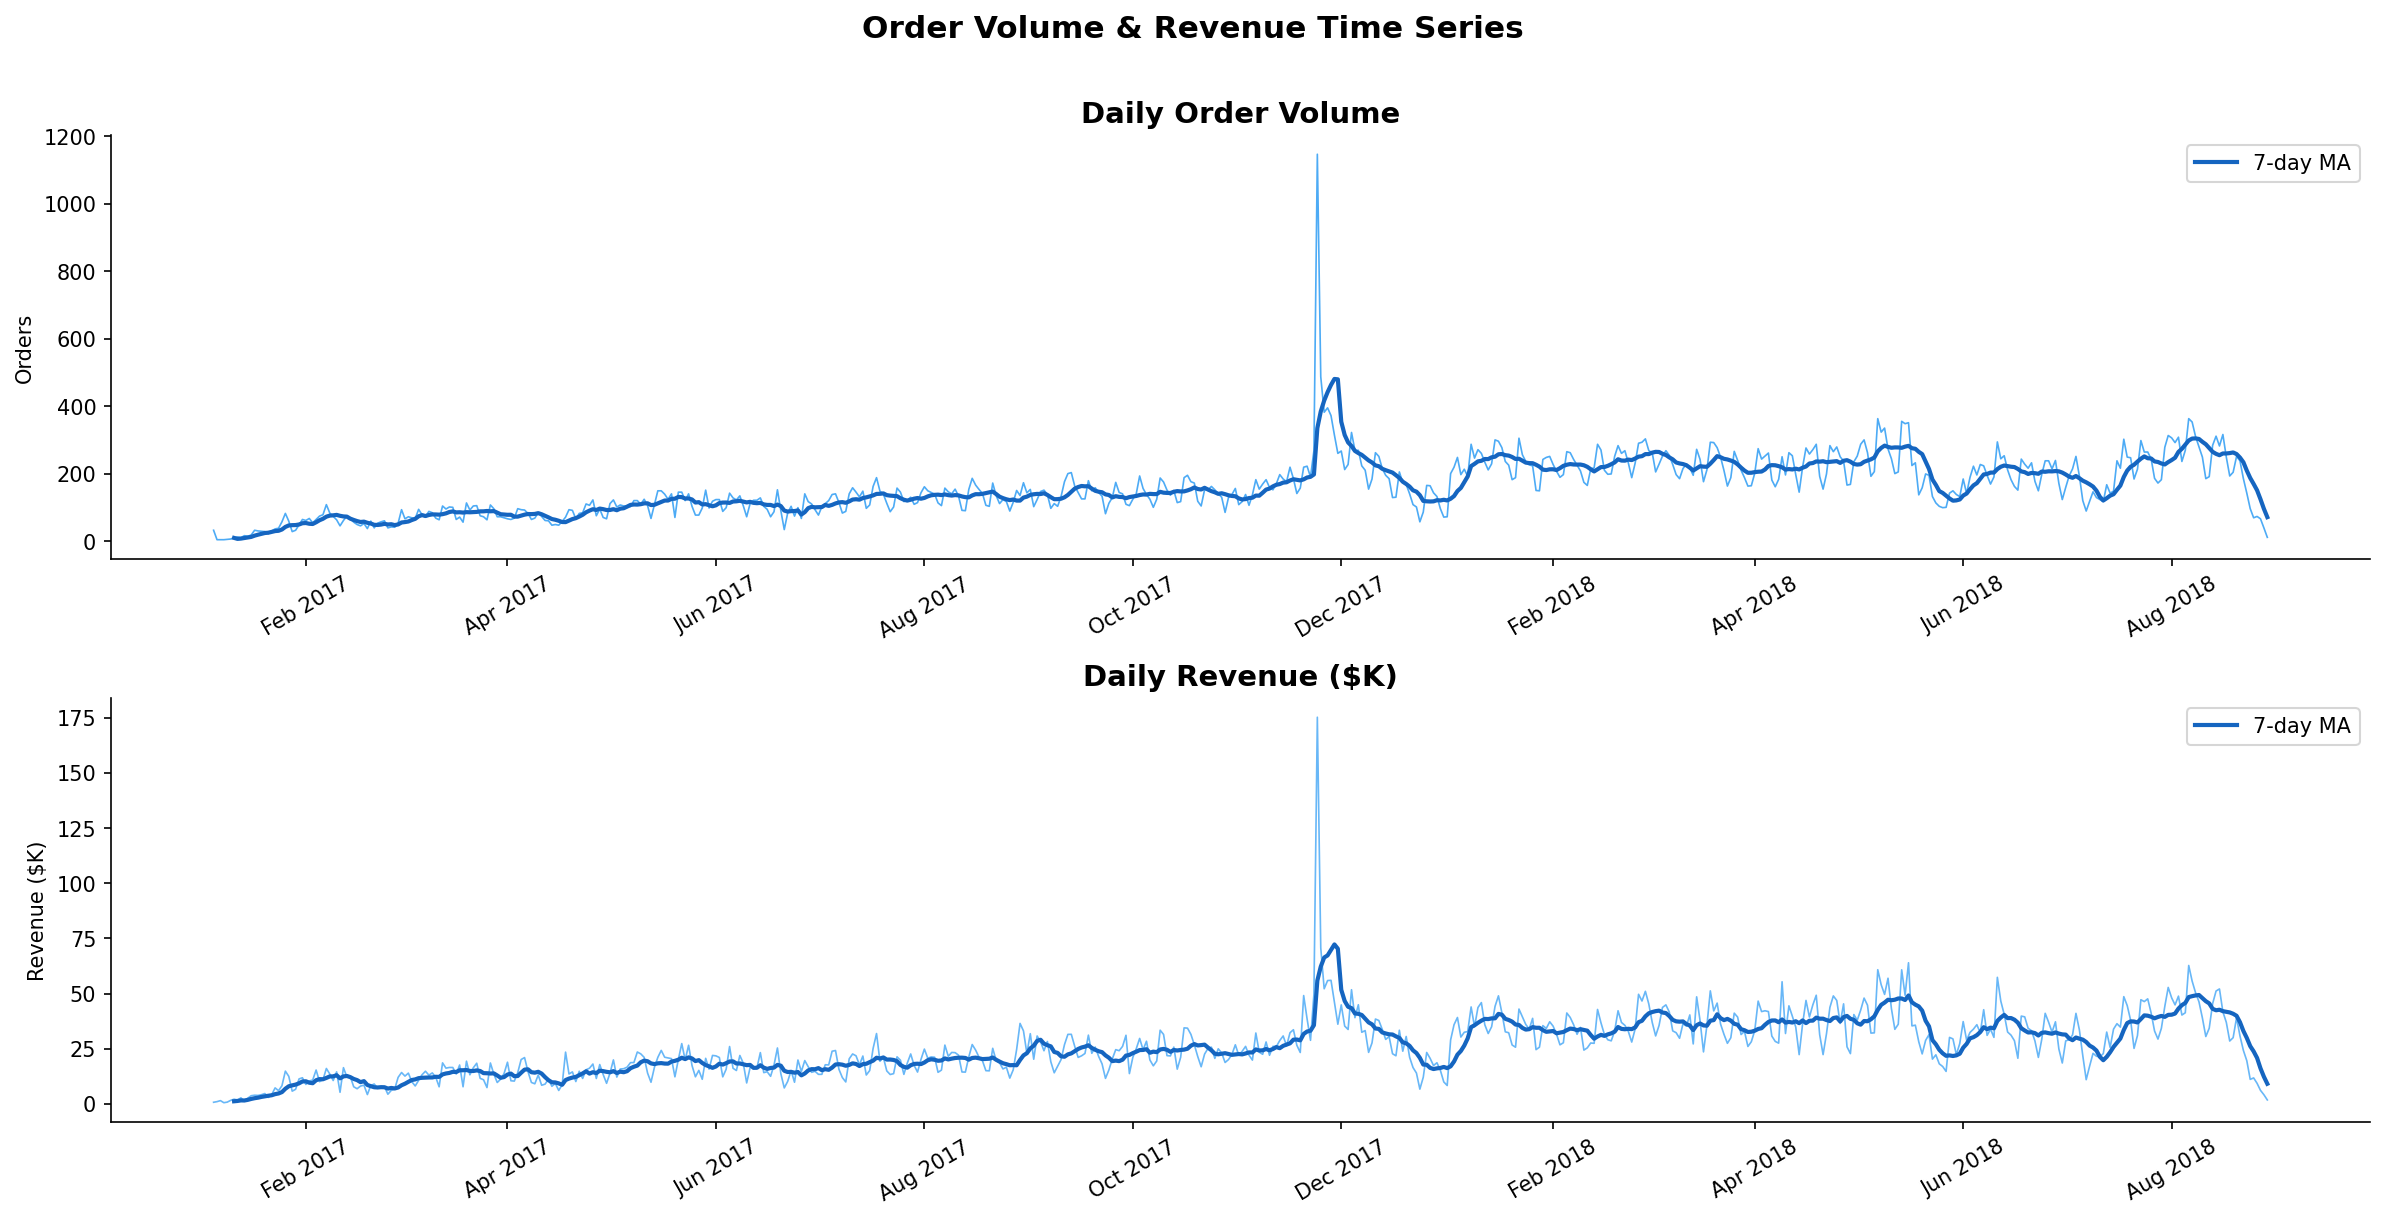

In [2]:
# ── Daily order volume + revenue ──────────────────────────────────────────────
daily = sql("""
    SELECT
        DATE(order_purchase_timestamp)      AS ds,
        COUNT(DISTINCT order_id)            AS num_orders,
        ROUND(SUM(total_payment), 2)        AS revenue,
        ROUND(AVG(total_payment), 2)        AS avg_order_value,
        ROUND(AVG(review_score), 2)         AS avg_review,
        COUNT(DISTINCT customer_unique_id)  AS unique_customers
    FROM master_orders
    WHERE order_status = 'delivered'
      AND order_purchase_timestamp >= '2017-01-01'
      AND order_purchase_timestamp <  '2018-09-01'
    GROUP BY DATE(order_purchase_timestamp)
    ORDER BY ds
""")

daily["ds"] = pd.to_datetime(daily["ds"])

# Fill missing dates with 0
date_range = pd.date_range(daily["ds"].min(), daily["ds"].max(), freq="D")
daily = (daily.set_index("ds")
               .reindex(date_range)
               .fillna(0)
               .reset_index()
               .rename(columns={"index": "ds"}))

print(f"   Time series built")
print(f"   Date range : {daily.ds.min().date()} → {daily.ds.max().date()}")
print(f"   Total days : {len(daily):,}")
print(f"   Avg daily orders  : {daily.num_orders.mean():.0f}")
print(f"   Avg daily revenue : ${daily.revenue.mean():,.0f}")
print(f"   Peak orders in a day: {daily.num_orders.max():.0f}")

# ── Plot raw time series ──────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

axes[0].plot(daily["ds"], daily["num_orders"],
             color="#2196F3", linewidth=0.8, alpha=0.8)
axes[0].set_title("Daily Order Volume")
axes[0].set_ylabel("Orders")

# 7-day rolling average
daily["orders_7d_ma"] = daily["num_orders"].rolling(7).mean()
axes[0].plot(daily["ds"], daily["orders_7d_ma"],
             color="#1565C0", linewidth=2, label="7-day MA")
axes[0].legend()

axes[1].plot(daily["ds"], daily["revenue"] / 1e3,
             color="#42A5F5", linewidth=0.8, alpha=0.8)
axes[1].set_title("Daily Revenue ($K)")
axes[1].set_ylabel("Revenue ($K)")
daily["revenue_7d_ma"] = daily["revenue"].rolling(7).mean()
axes[1].plot(daily["ds"], daily["revenue_7d_ma"] / 1e3,
             color="#1565C0", linewidth=2, label="7-day MA")
axes[1].legend()

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30)

plt.suptitle("Order Volume & Revenue Time Series",
             fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\14_time_series_raw.png",
            bbox_inches="tight")
plt.show()

Augmented Dickey-Fuller Test:
   ADF Statistic : -2.9976
   p-value       : 0.0351
   Stationary    : Yes


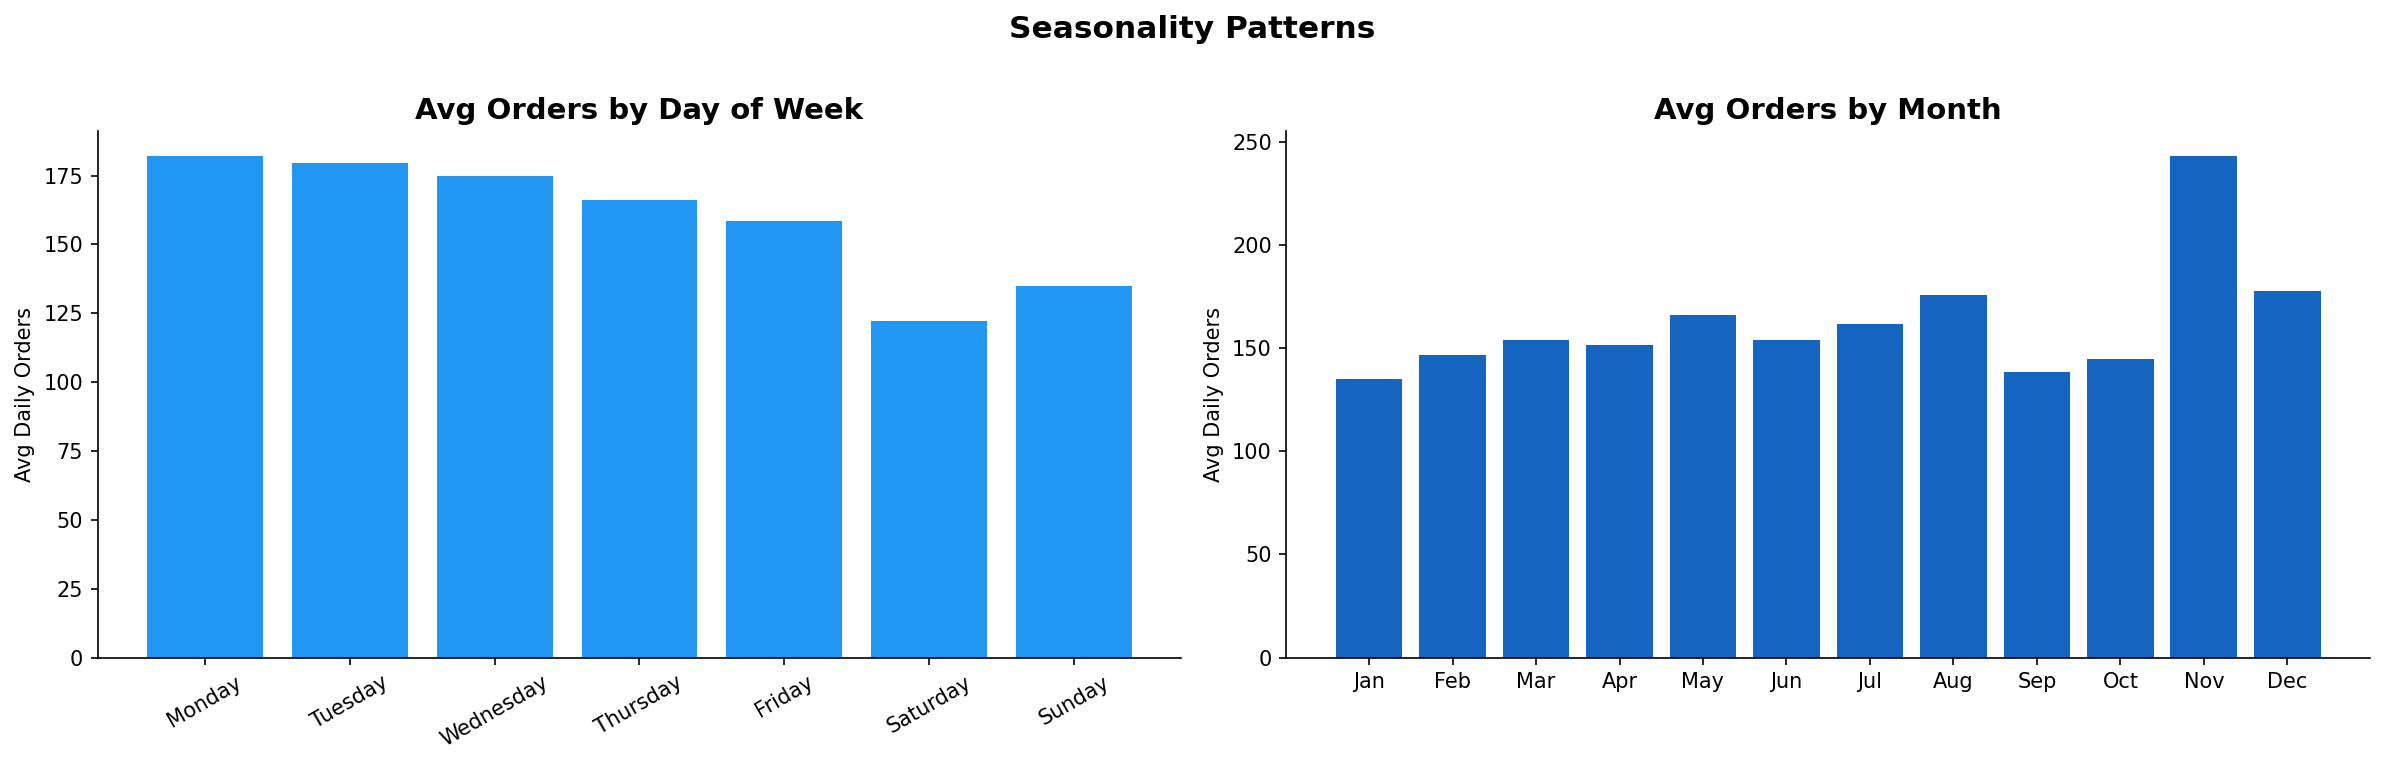

In [3]:
# ── ADF stationarity test ─────────────────────────────────────────────────────
adf_result = adfuller(daily["num_orders"].dropna())
print("Augmented Dickey-Fuller Test:")
print(f"   ADF Statistic : {adf_result[0]:.4f}")
print(f"   p-value       : {adf_result[1]:.4f}")
print(f"   Stationary    : {'Yes' if adf_result[1] < 0.05 else 'No'}")

# ── Seasonality analysis ──────────────────────────────────────────────────────
daily["day_of_week"] = daily["ds"].dt.day_name()
daily["month"]       = daily["ds"].dt.month
daily["week"]        = daily["ds"].dt.isocalendar().week.astype(int)

dow_avg = (daily.groupby("day_of_week")["num_orders"]
           .mean()
           .reindex(["Monday","Tuesday","Wednesday",
                     "Thursday","Friday","Saturday","Sunday"]))

month_avg = (daily.groupby("month")["num_orders"].mean())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(dow_avg.index, dow_avg.values, color="#2196F3")
axes[0].set_title("Avg Orders by Day of Week")
axes[0].set_ylabel("Avg Daily Orders")
axes[0].tick_params(axis="x", rotation=30)

month_names = ["Jan","Feb","Mar","Apr","May","Jun",
               "Jul","Aug","Sep","Oct","Nov","Dec"]
axes[1].bar([month_names[m-1] for m in month_avg.index],
            month_avg.values, color="#1565C0")
axes[1].set_title("Avg Orders by Month")
axes[1].set_ylabel("Avg Daily Orders")

plt.suptitle("Seasonality Patterns",
             fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\15_seasonality.png",
            bbox_inches="tight")
plt.show()

Train: 542 days  |  Test (holdout): 60 days


00:28:39 - cmdstanpy - INFO - Chain [1] start processing
00:28:40 - cmdstanpy - INFO - Chain [1] done processing



Prophet Holdout Evaluation (last 60 days):
   MAPE : 67.0%
   RMSE : 73.7 orders/day


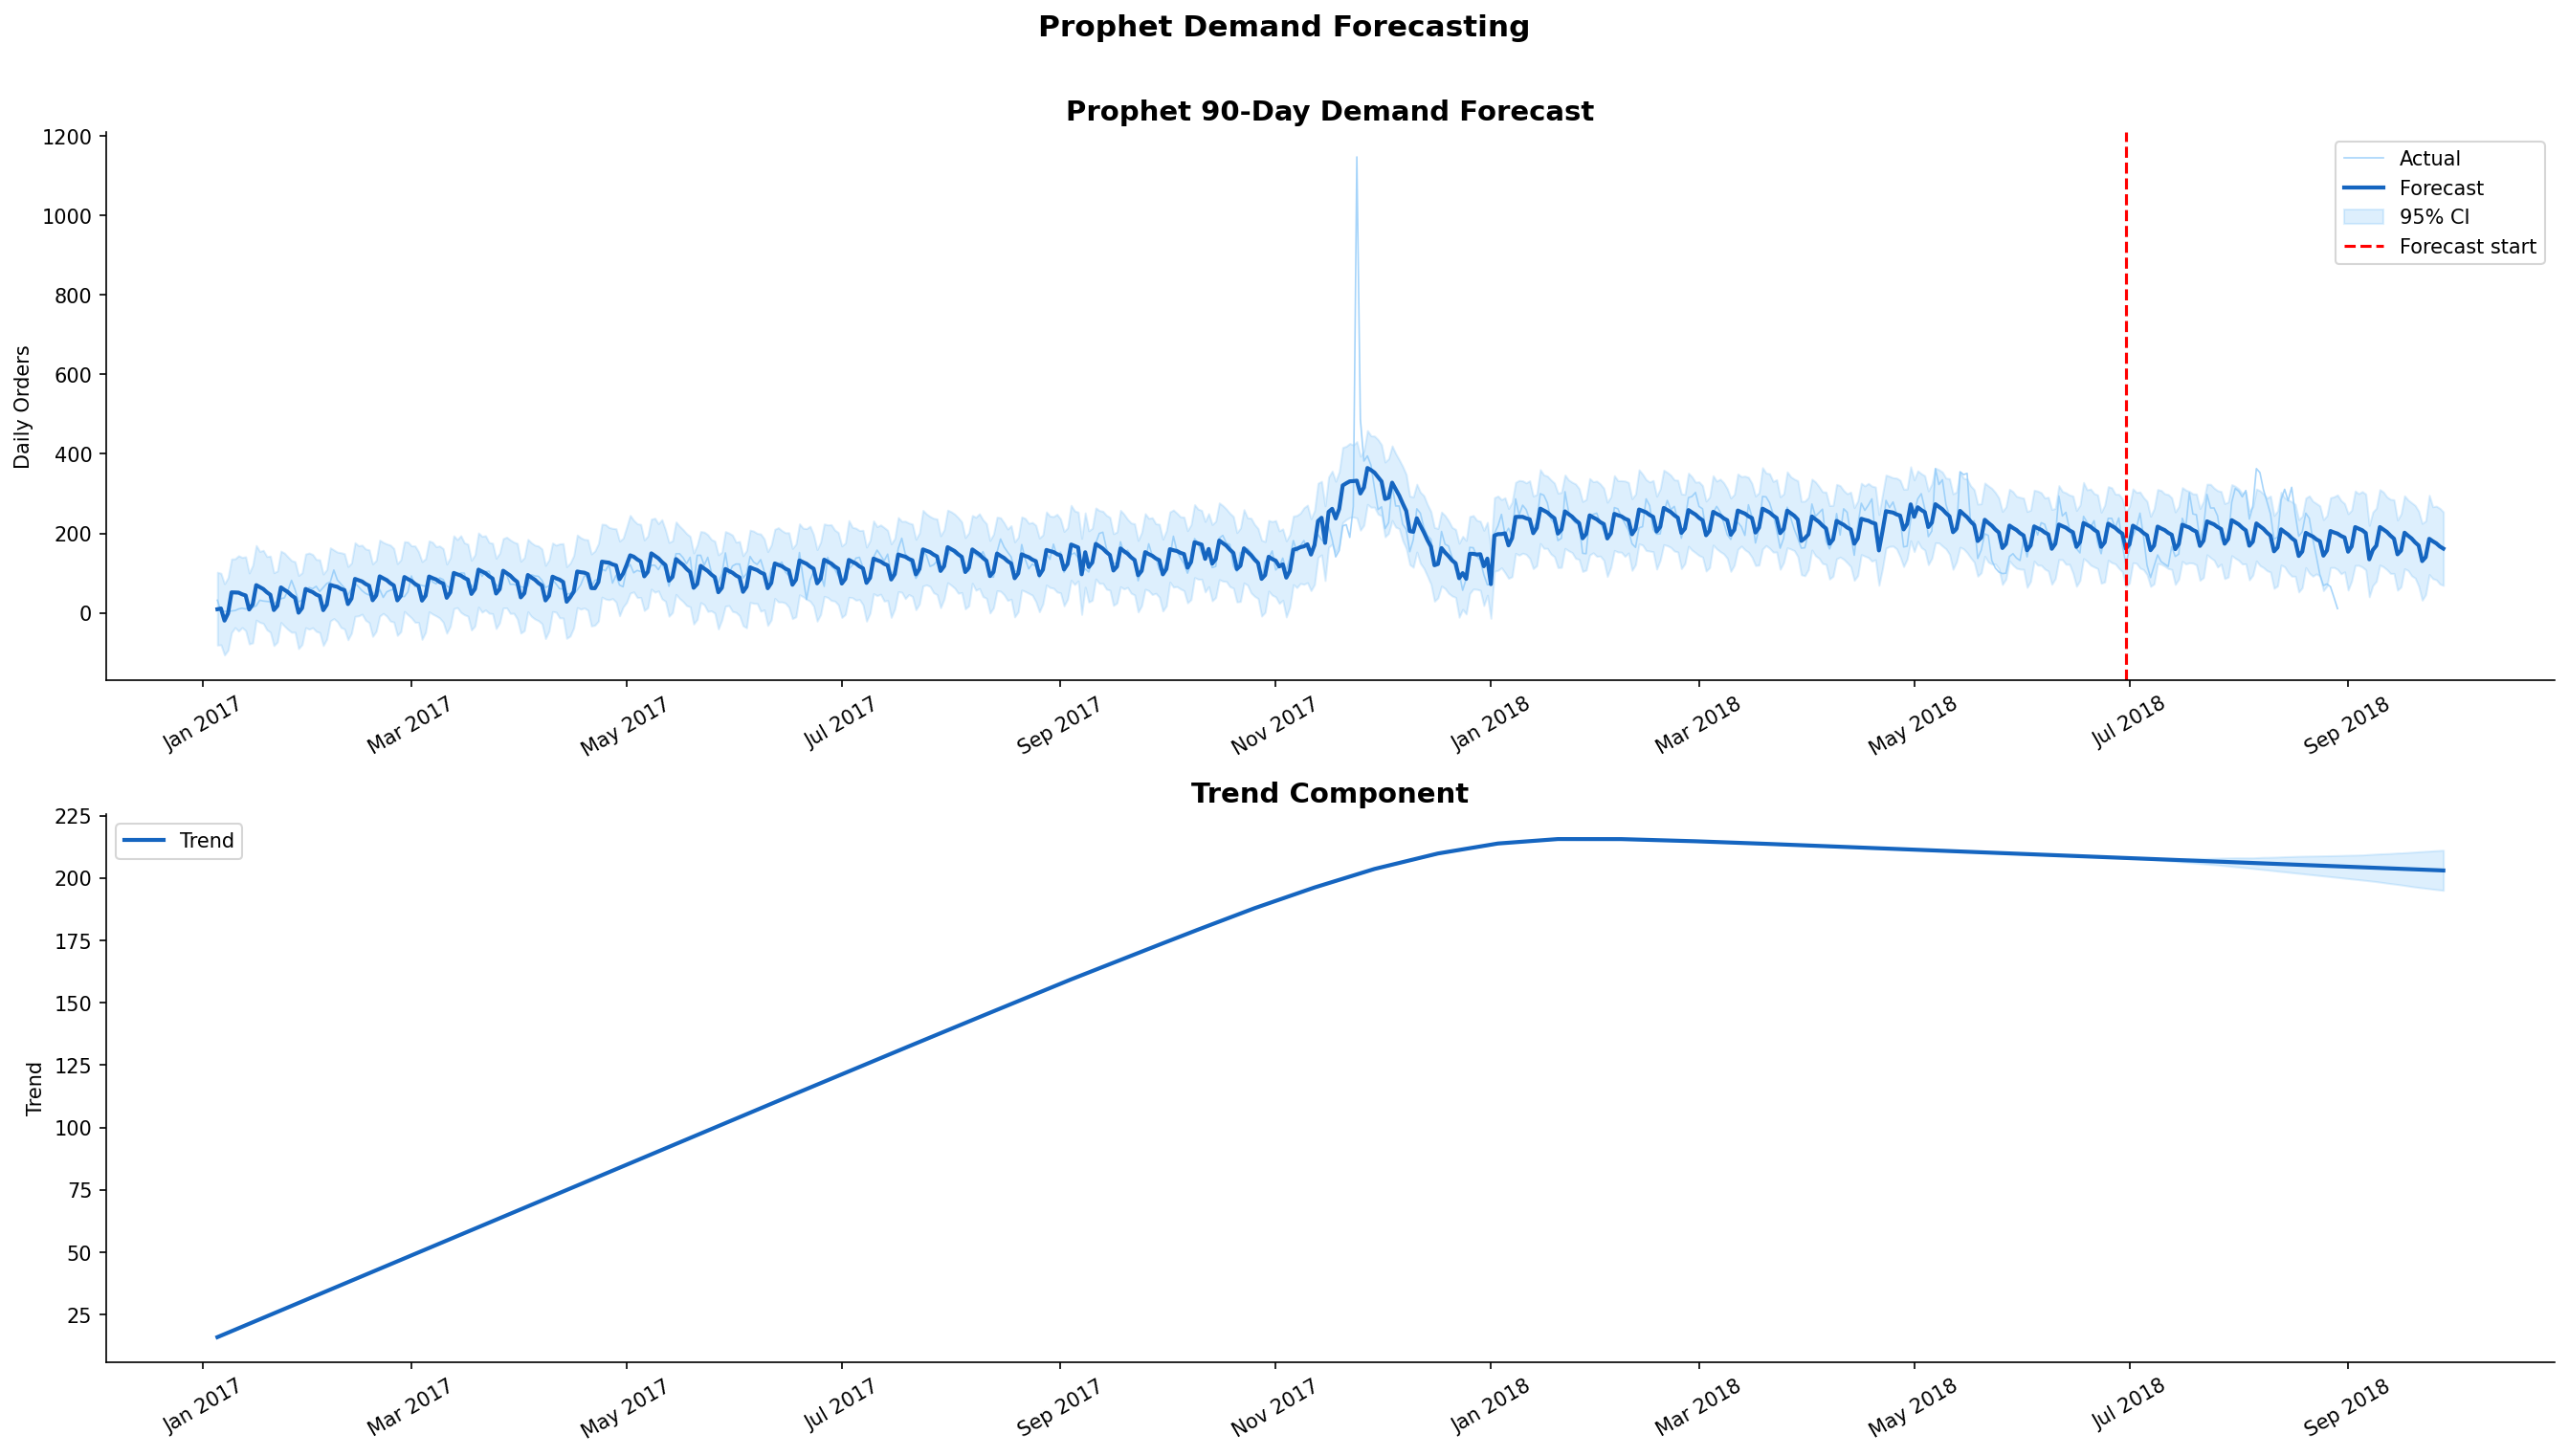


Next 90-day forecast:
   Avg daily orders : 180
   Peak day forecast: 216 orders
   Total forecasted : 5392 orders


In [4]:
# ── Prepare Prophet data ──────────────────────────────────────────────────────
prophet_df = daily[["ds", "num_orders"]].rename(
    columns={"num_orders": "y"})

# Train/test split — last 60 days as holdout
HOLDOUT = 60
train_df = prophet_df.iloc[:-HOLDOUT]
test_df  = prophet_df.iloc[-HOLDOUT:]

print(f"Train: {len(train_df)} days  |  Test (holdout): {len(test_df)} days")

# ── Fit Prophet ───────────────────────────────────────────────────────────────
model = Prophet(
    changepoint_prior_scale  = 0.05,
    seasonality_prior_scale  = 10,
    yearly_seasonality       = True,
    weekly_seasonality       = True,
    daily_seasonality        = False,
    interval_width           = 0.95,
)
model.add_country_holidays(country_name="BR")
model.fit(train_df)

# ── Forecast 90 days ahead ────────────────────────────────────────────────────
future    = model.make_future_dataframe(periods=90)
forecast  = model.predict(future)

# ── Evaluate on holdout ───────────────────────────────────────────────────────
holdout_forecast = forecast[forecast["ds"].isin(test_df["ds"])]
y_true = test_df["y"].values
y_pred = holdout_forecast["yhat"].values

mape = mean_absolute_percentage_error(y_true, y_pred) * 100
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"\nProphet Holdout Evaluation (last 60 days):")
print(f"   MAPE : {mape:.1f}%")
print(f"   RMSE : {rmse:.1f} orders/day")

# ── Plot forecast ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(18, 10))

# Full forecast
axes[0].plot(prophet_df["ds"], prophet_df["y"],
             color="#90CAF9", linewidth=0.8, label="Actual", alpha=0.8)
axes[0].plot(forecast["ds"], forecast["yhat"],
             color="#1565C0", linewidth=2, label="Forecast")
axes[0].fill_between(forecast["ds"],
                     forecast["yhat_lower"],
                     forecast["yhat_upper"],
                     alpha=0.15, color="#2196F3", label="95% CI")
axes[0].axvline(train_df["ds"].max(), color="red",
                linestyle="--", linewidth=1.5, label="Forecast start")
axes[0].set_title("Prophet 90-Day Demand Forecast")
axes[0].set_ylabel("Daily Orders")
axes[0].legend()

# Components
axes[1].plot(forecast["ds"], forecast["trend"],
             color="#1565C0", linewidth=2, label="Trend")
axes[1].fill_between(forecast["ds"],
                     forecast["trend_lower"],
                     forecast["trend_upper"],
                     alpha=0.15, color="#2196F3")
axes[1].set_title("Trend Component")
axes[1].set_ylabel("Trend")
axes[1].legend()

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30)

plt.suptitle("Prophet Demand Forecasting",
             fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\16_prophet_forecast.png",
            bbox_inches="tight")
plt.show()

print(f"\nNext 90-day forecast:")
future_only = forecast[forecast["ds"] > prophet_df["ds"].max()]
print(f"   Avg daily orders : {future_only['yhat'].mean():.0f}")
print(f"   Peak day forecast: {future_only['yhat'].max():.0f} orders")
print(f"   Total forecasted : {future_only['yhat'].sum():.0f} orders")

Fitting ARIMA model...

Model Comparison (60-day holdout):
  Model            MAPE      RMSE
  ------------------------------------
  Prophet         67.0%      73.7
  ARIMA           68.6%      83.0
  Winner        Prophet


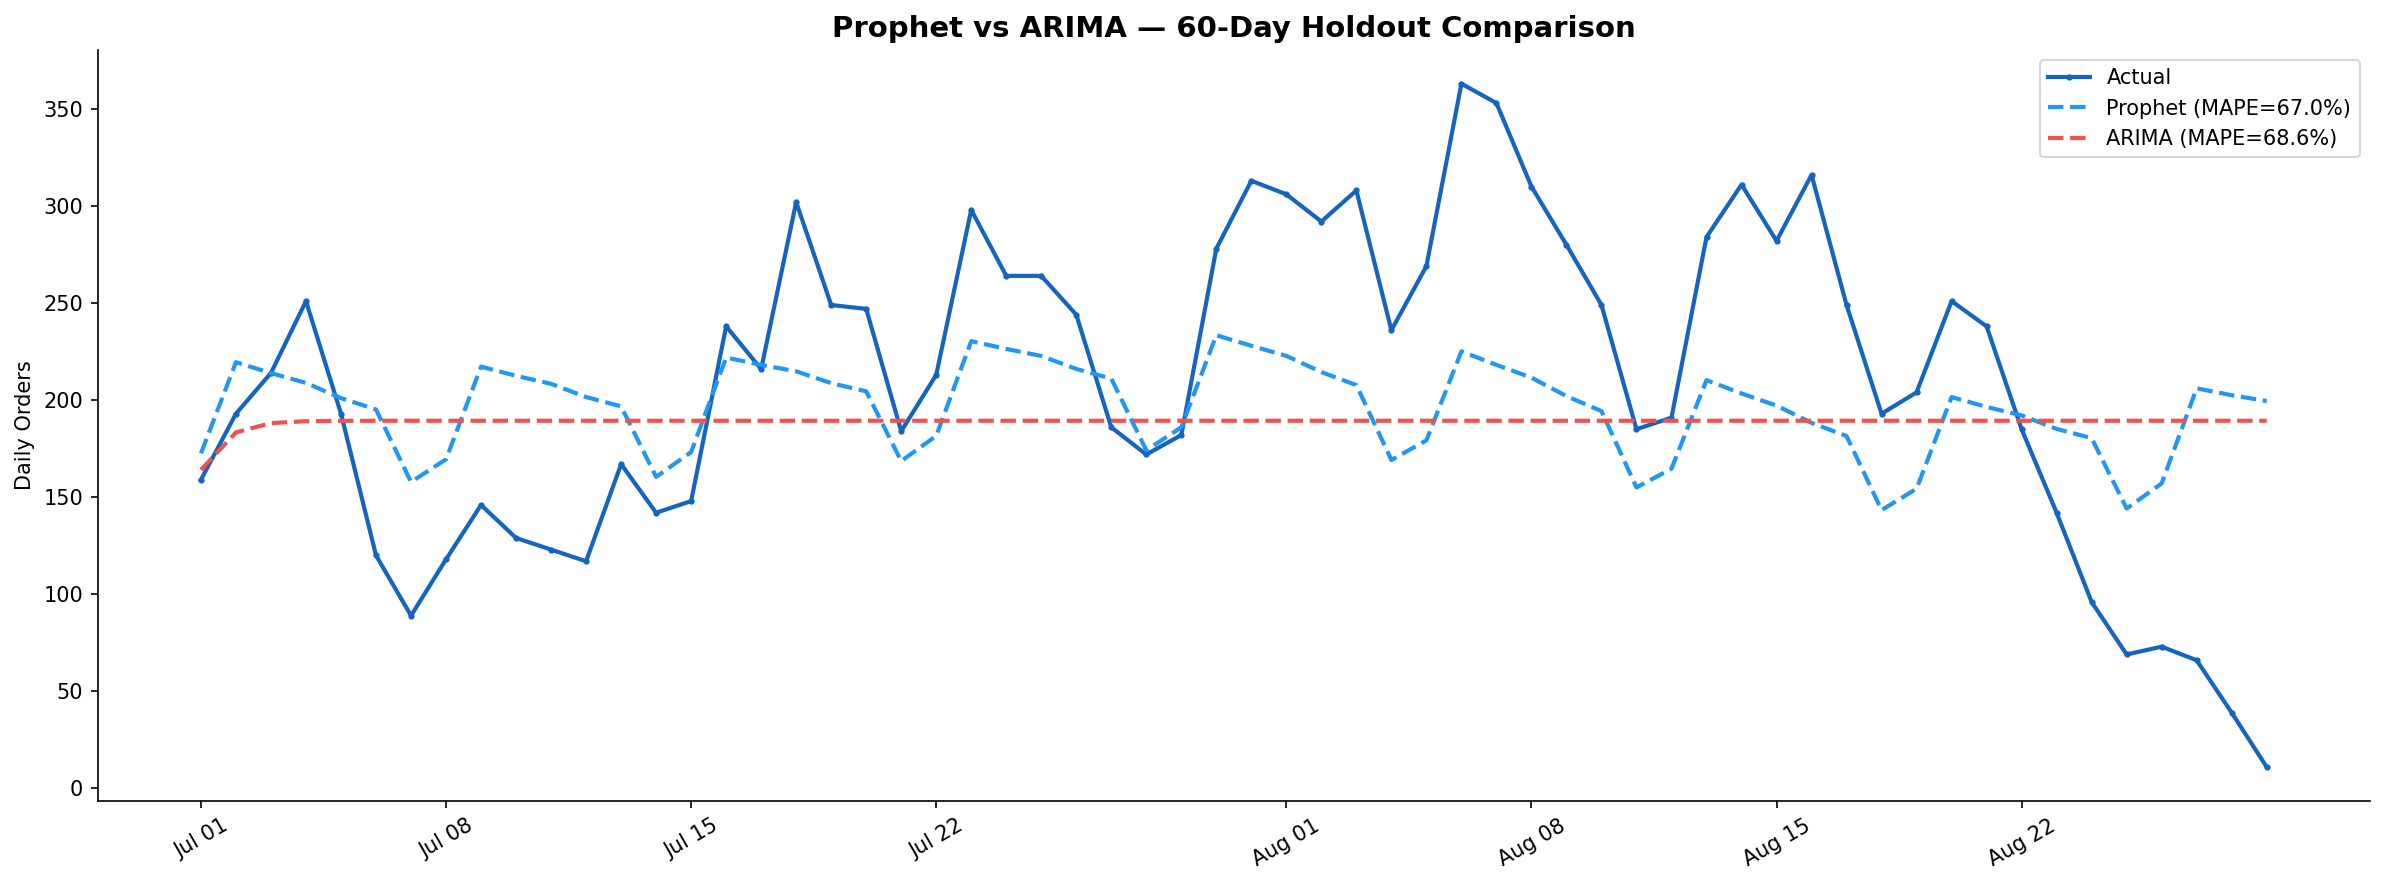

In [5]:
# ── ARIMA for comparison ──────────────────────────────────────────────────────
print("Fitting ARIMA model...")

train_arima = train_df["y"].values
arima_model = ARIMA(train_arima, order=(2, 1, 2))
arima_fit   = arima_model.fit()

arima_pred  = arima_fit.forecast(steps=HOLDOUT)
arima_mape  = mean_absolute_percentage_error(y_true, arima_pred) * 100
arima_rmse  = np.sqrt(mean_squared_error(y_true, arima_pred))

print(f"\nModel Comparison (60-day holdout):")
print(f"{'='*40}")
print(f"  {'Model':<12} {'MAPE':>8}  {'RMSE':>8}")
print(f"  {'-'*36}")
print(f"  {'Prophet':<12} {mape:>7.1f}%  {rmse:>8.1f}")
print(f"  {'ARIMA':<12} {arima_mape:>7.1f}%  {arima_rmse:>8.1f}")
print(f"  {'Winner':<12} {'Prophet' if mape < arima_mape else 'ARIMA':>8}")
print(f"{'='*40}")

# Plot comparison
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(test_df["ds"].values, y_true,
        color="#1565C0", linewidth=2, label="Actual", marker="o", markersize=2)
ax.plot(test_df["ds"].values, y_pred,
        color="#2196F3", linewidth=2, linestyle="--",
        label=f"Prophet (MAPE={mape:.1f}%)")
ax.plot(test_df["ds"].values, arima_pred,
        color="#EF5350", linewidth=2, linestyle="--",
        label=f"ARIMA (MAPE={arima_mape:.1f}%)")

ax.set_title("Prophet vs ARIMA — 60-Day Holdout Comparison")
ax.set_ylabel("Daily Orders")
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=30)

plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\17_prophet_vs_arima.png",
            bbox_inches="tight")
plt.show()

In [7]:
# ── Build automated Excel report ──────────────────────────────────────────────
EXCEL_PATH = r"D:\customer_intelligence_platform\outputs\forecast_report.xlsx"

# Prepare data
monthly_actual = (
    daily.groupby(daily["ds"].dt.to_period("M"))
    .agg(total_orders=("num_orders","sum"),
         total_revenue=("revenue","sum"),
         avg_daily_orders=("num_orders","mean"))
    .reset_index()
)
monthly_actual["ds"] = monthly_actual["ds"].astype(str)

future_90 = forecast[forecast["ds"] > prophet_df["ds"].max()].copy()
future_90["month"] = future_90["ds"].dt.to_period("M")
monthly_forecast = (
    future_90.groupby("month")
    .agg(forecasted_orders =("yhat",      "sum"),
         forecast_low      =("yhat_lower","sum"),
         forecast_high     =("yhat_upper","sum"))
    .reset_index()
)
monthly_forecast["month"] = monthly_forecast["month"].astype(str)

wb = openpyxl.Workbook()

# ── Helper styles ─────────────────────────────────────────────────────────────
BLUE_FILL   = PatternFill("solid", fgColor="1565C0")
LIGHT_FILL  = PatternFill("solid", fgColor="BBDEFB")
HEADER_FONT = Font(bold=True, color="FFFFFF", size=11)
TITLE_FONT  = Font(bold=True, size=14, color="1565C0")
BORDER      = Border(
    left=Side(style="thin"), right=Side(style="thin"),
    top=Side(style="thin"),  bottom=Side(style="thin"))

def style_header_row(ws, row, num_cols):
    for col in range(1, num_cols + 1):
        cell = ws.cell(row=row, column=col)
        cell.fill = BLUE_FILL
        cell.font = HEADER_FONT
        cell.alignment = Alignment(horizontal="center")
        cell.border = BORDER

def style_data_row(ws, row, num_cols, shade=False):
    for col in range(1, num_cols + 1):
        cell = ws.cell(row=row, column=col)
        if shade:
            cell.fill = LIGHT_FILL
        cell.border = BORDER
        cell.alignment = Alignment(horizontal="center")

# ── Sheet 1: Executive Summary ────────────────────────────────────────────────
ws1 = wb.active
ws1.title = "Executive Summary"
ws1.column_dimensions["A"].width = 35
ws1.column_dimensions["B"].width = 25

ws1["A1"] = "Customer Intelligence Platform"
ws1["A1"].font = Font(bold=True, size=16, color="1565C0")
ws1["A2"] = "Automated Forecast Report — Olist E-Commerce"
ws1["A2"].font = Font(italic=True, size=11, color="555555")
ws1["A3"] = f"Generated: {pd.Timestamp.now().strftime('%B %d, %Y')}"

ws1["A5"] = "KEY BUSINESS METRICS"
ws1["A5"].font = Font(bold=True, size=12, color="1565C0")

kpis = [
    ("Total Orders (Delivered)",     f"{96478:,}"),
    ("Total Revenue",                f"${15422462:,.0f}"),
    ("Avg Order Value",              f"${159.86:.2f}"),
    ("Unique Customers",             f"{93358:,}"),
    ("Avg Review Score",             f"4.15 / 5.0"),
    ("Avg Delivery Days",            f"12.1 days"),
    ("% Late Orders",                f"7.6%"),
    ("Churn Rate",                   f"70.6%"),
    ("Revenue at Risk (High+Crit)",  f"$8,856,613"),
    ("Prophet Forecast MAPE",        f"{mape:.1f}%"),
    ("ARIMA Forecast MAPE",          f"{arima_mape:.1f}%"),
    ("Forecasted Orders (90 days)",  f"{future_only['yhat'].sum():,.0f}"),
]

style_header_row(ws1, 6, 2)
ws1["A6"] = "Metric"
ws1["B6"] = "Value"

for i, (metric, value) in enumerate(kpis, start=7):
    ws1[f"A{i}"] = metric
    ws1[f"B{i}"] = value
    style_data_row(ws1, i, 2, shade=(i % 2 == 0))

# ── Sheet 2: Monthly Actuals ──────────────────────────────────────────────────
ws2 = wb.create_sheet("Monthly Actuals")
headers = ["Month", "Total Orders", "Total Revenue ($)", "Avg Daily Orders"]
for col, h in enumerate(headers, 1):
    ws2.cell(row=1, column=col, value=h)
    ws2.column_dimensions[openpyxl.utils.get_column_letter(col)].width = 22
style_header_row(ws2, 1, len(headers))

for i, row in enumerate(monthly_actual.itertuples(), start=2):
    ws2.cell(row=i, column=1, value=str(row.ds))
    ws2.cell(row=i, column=2, value=int(row.total_orders))
    ws2.cell(row=i, column=3, value=round(float(row.total_revenue), 2))
    ws2.cell(row=i, column=4, value=round(float(row.avg_daily_orders), 1))
    style_data_row(ws2, i, len(headers), shade=(i % 2 == 0))

# Add bar chart
chart1 = BarChart()
chart1.title = "Monthly Order Volume"
chart1.style = 10
chart1.y_axis.title = "Orders"
chart1.x_axis.title = "Month"
data_ref   = Reference(ws2, min_col=2, min_row=1,
                        max_row=len(monthly_actual)+1)
cats_ref   = Reference(ws2, min_col=1, min_row=2,
                        max_row=len(monthly_actual)+1)
chart1.add_data(data_ref, titles_from_data=True)
chart1.set_categories(cats_ref)
chart1.shape = 4
chart1.width = 25
chart1.height = 14
ws2.add_chart(chart1, "F2")

# ── Sheet 3: 90-Day Forecast ──────────────────────────────────────────────────
ws3 = wb.create_sheet("90-Day Forecast")
f_headers = ["Month", "Forecasted Orders",
             "Low Estimate", "High Estimate"]
for col, h in enumerate(f_headers, 1):
    ws3.cell(row=1, column=col, value=h)
    ws3.column_dimensions[openpyxl.utils.get_column_letter(col)].width = 22
style_header_row(ws3, 1, len(f_headers))

for i, row in enumerate(monthly_forecast.itertuples(), start=2):
    ws3.cell(row=i, column=1, value=str(row.month))
    ws3.cell(row=i, column=2, value=round(float(row.forecasted_orders), 0))
    ws3.cell(row=i, column=3, value=round(float(row.forecast_low), 0))
    ws3.cell(row=i, column=4, value=round(float(row.forecast_high), 0))
    style_data_row(ws3, i, len(f_headers), shade=(i % 2 == 0))

# Forecast line chart
chart2 = LineChart()
chart2.title = "90-Day Order Forecast"
chart2.style = 10
chart2.y_axis.title = "Forecasted Orders"
chart2.x_axis.title = "Month"
data_ref2 = Reference(ws3, min_col=2, min_row=1,
                       max_row=len(monthly_forecast)+1)
chart2.add_data(data_ref2, titles_from_data=True)
chart2.width  = 25
chart2.height = 14
ws3.add_chart(chart2, "F2")

# ── Sheet 4: Churn Risk ───────────────────────────────────────────────────────
ws4 = wb.create_sheet("Churn Risk Summary")
churn_summary = [
    ("Low Risk",      10292, 1793849, 174, "16%"),
    ("Medium Risk",   27527, 4771999, 173, "42%"),
    ("High Risk",     32997, 5535037, 168, "60%"),
    ("Critical Risk", 22580, 3321574, 147, "78%"),
]
c_headers = ["Risk Tier","Customers","Revenue ($)",
             "Avg Spend ($)","Avg Churn Prob"]
for col, h in enumerate(c_headers, 1):
    ws4.cell(row=1, column=col, value=h)
    ws4.column_dimensions[openpyxl.utils.get_column_letter(col)].width = 20
style_header_row(ws4, 1, len(c_headers))

for i, row in enumerate(churn_summary, start=2):
    for col, val in enumerate(row, 1):
        ws4.cell(row=i, column=col, value=val)
    style_data_row(ws4, i, len(c_headers), shade=(i % 2 == 0))

ws4.cell(row=7, column=1, value="TOTAL AT RISK (High+Critical)")
ws4.cell(row=7, column=2, value=55577)
ws4.cell(row=7, column=3, value=8856613)
ws4["A7"].font = Font(bold=True, color="C62828")
ws4["B7"].font = Font(bold=True, color="C62828")
ws4["C7"].font = Font(bold=True, color="C62828")

wb.save(EXCEL_PATH)
print(f"Excel report saved → {EXCEL_PATH}")
print(f"\nSheets created:")
print(f"   1. Executive Summary  — all KPIs in one place")
print(f"   2. Monthly Actuals    — historical data + bar chart")
print(f"   3. 90-Day Forecast    — Prophet output + line chart")
print(f"   4. Churn Risk Summary — risk tiers + revenue at stake")

Excel report saved → D:\customer_intelligence_platform\outputs\forecast_report.xlsx

Sheets created:
   1. Executive Summary  — all KPIs in one place
   2. Monthly Actuals    — historical data + bar chart
   3. 90-Day Forecast    — Prophet output + line chart
   4. Churn Risk Summary — risk tiers + revenue at stake
